# 04 · Market Balances: Finding Co-moving Groups and Counterweights, and How Much History They Need

**Author:** Juan Antonio Sainz Gálvez · Applied AI & ML, Conestoga College

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/04_market_balances.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

## Abstract

*Equilibra* is a tool I built so investors can study the market, with their own AI assistant, as a set of **balances**: groups of assets that move together and the counterweights that move against them. It is delivered as a connector (MCP server) that any assistant can call, and it measures; it never recommends trades. Its daily view uses the **last five business days**, because that is what an investor feels this week.

That design choice raises a research question: a correlation matrix estimated from five observations is mostly noise. This notebook reviews the literature on correlation structure in markets (random matrix theory, hierarchical clustering, shrinkage, crisis correlations) and runs three experiments on public data (20 large US stocks and 5 factor ETFs, 2014–2022): **(1)** separate signal from noise with random matrix theory, **(2)** recover the balances with hierarchical clustering after removing the market mode, and **(3)** measure how well correlations estimated over 5 to 250 days predict the next quarter, with and without shrinkage toward a long-run anchor.


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})

def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec="none"))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
            color=text_color, fontsize=fontsize, fontweight="bold", wrap=True)

def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


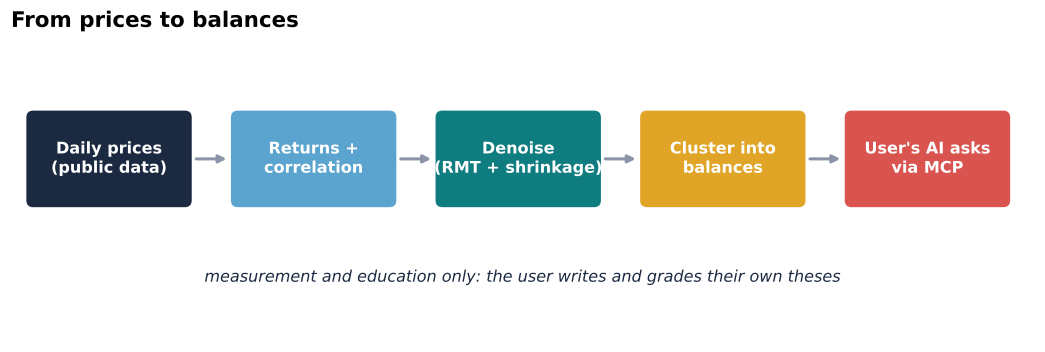

In [2]:
# Infographic: how Equilibra turns prices into balances
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 3.6); ax.axis("off")
steps = [("Daily prices\n(public data)", PALETTE["navy"]), ("Returns +\ncorrelation", PALETTE["sky"]),
         ("Denoise\n(RMT + shrinkage)", PALETTE["teal"]), ("Cluster into\nbalances", PALETTE["gold"]),
         ("User's AI asks\nvia MCP", PALETTE["coral"])]
for i, (t, c) in enumerate(steps):
    box(ax, (0.2 + i * 2.4, 1.6), 1.9, 1.1, t, c, fontsize=10.5)
    if i < len(steps) - 1:
        arrow(ax, (2.1 + i * 2.4, 2.15), (2.6 + i * 2.4, 2.15))
ax.text(6.0, 0.7, "measurement and education only: the user writes and grades their own theses",
        ha="center", fontsize=10.5, color=PALETTE["navy"], style="italic")
ax.set_title("From prices to balances", pad=6)
plt.show()

## 1. Literature review

### 1.1 Correlations are mostly noise, except a few directions
Laloux, Cizeau, Bouchaud and Potters compared the eigenvalues of empirical stock correlation matrices with those of purely random matrices (the Marchenko–Pastur law) and found that most eigenvalues fall inside the random band; only a few, led by a large "market mode", carry information [1]. Plerou et al. reached the same conclusion independently and showed that the information-bearing eigenvectors correspond to industry sectors [2]. The practical consequence: a raw sample correlation matrix should be cleaned before it is used for decisions.

### 1.2 Hierarchies and clusters
Mantegna introduced the idea of reading a correlation matrix as a distance, d = √(2(1−ρ)), and building a hierarchical tree (minimum spanning tree) that recovers economic sectors without being told them [3]. Two decades of follow-up work on correlation networks and clustering are reviewed by Marti et al. [4]. López de Prado turned the same hierarchy into a portfolio method, Hierarchical Risk Parity, which allocates risk across clusters instead of inverting a noisy covariance matrix [5].

### 1.3 Shrinkage
When there are few observations per asset, Ledoit and Wolf show that pulling the sample covariance toward a structured target with an optimal intensity reduces estimation error [6]. Shrinkage is the standard remedy when the window is short, which is exactly the case for a five-day view.

### 1.4 Correlations rise in crises
Longin and Solnik show with extreme-value theory that correlation between equity markets increases in bear markets, not in bull markets [7]: diversification fails when it is needed most. A balance that looks stable in calm weeks can collapse into a single market mode in a crisis.

### 1.5 LLM assistants as the interface
Multi-agent LLM frameworks for financial analysis, such as TradingAgents, assign analyst roles to LLM agents that read market data and debate [8]. Equilibra takes the opposite design: the measurement is deterministic and lives in the connector; the user's assistant only asks for it and explains it, so the numbers are the same whichever AI the user brings.

**Gap.** The literature studies windows of months to years. Tools used by retail investors show weekly views. How much information does a five-day correlation carry, and how should it be combined with a longer anchor?


In [3]:
try:
    import skfolio  # noqa: F401
except ImportError:          # Colab: install the open-source library that ships the public datasets
    %pip install -q skfolio

import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf
from skfolio.datasets import load_sp500_dataset, load_factors_dataset   # public datasets shipped with skfolio

stocks = load_sp500_dataset()
factors = load_factors_dataset()
prices = stocks.join(factors, how="inner").loc["2014":]
returns = np.log(prices).diff().dropna()
SECTOR = {"AAPL": "tech", "AMD": "tech", "MSFT": "tech", "BAC": "banks", "JPM": "banks",
          "CVX": "energy", "XOM": "energy", "RRC": "energy", "KO": "staples", "PEP": "staples",
          "PG": "staples", "WMT": "staples", "JNJ": "health", "LLY": "health", "MRK": "health",
          "PFE": "health", "UNH": "health", "HD": "consumer", "BBY": "consumer", "GE": "industrial",
          "MTUM": "factor ETF", "QUAL": "factor ETF", "SIZE": "factor ETF", "USMV": "factor ETF", "VLUE": "factor ETF"}
print(f"{returns.shape[1]} assets · {len(returns):,} trading days · {returns.index[0].date()} to {returns.index[-1].date()}")

25 assets · 2,263 trading days · 2014-01-03 to 2022-12-28


## 2. Experiment 1: how many directions carry information?

For N assets and T days of independent noise, the eigenvalues of the correlation matrix fall below λ₊ = (1 + √(N/T))² (Marchenko–Pastur). Eigenvalues above the bound carry signal [1, 2].


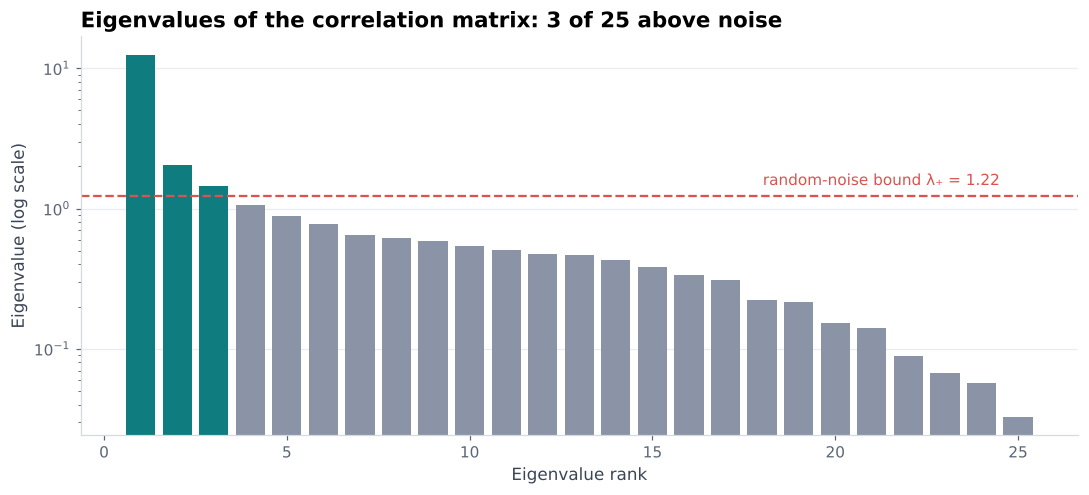

Market mode explains 50% of total variance; next 2 signal directions: 14%


In [4]:
C = returns.corr()
N, T = returns.shape[1], len(returns)
eig = np.sort(np.linalg.eigvalsh(C.values))[::-1]
lam_plus = (1 + np.sqrt(N / T)) ** 2
n_signal = int((eig > lam_plus).sum())

fig, ax = plt.subplots(figsize=(10, 4.6))
cols = [PALETTE["teal"] if e > lam_plus else PALETTE["grey"] for e in eig]
ax.bar(range(1, N + 1), eig, color=cols)
ax.axhline(lam_plus, color=PALETTE["coral"], ls="--", lw=1.5)
ax.text(N - 0.5, lam_plus + 0.25, f"random-noise bound λ₊ = {lam_plus:.2f}", ha="right", color=PALETTE["coral"], fontsize=10)
ax.set_yscale("log"); ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
ax.set_title(f"Eigenvalues of the correlation matrix: {n_signal} of {N} above noise")
ax.set_xlabel("Eigenvalue rank"); ax.set_ylabel("Eigenvalue (log scale)")
plt.tight_layout(); plt.show()
C_raw = C
print(f"Market mode explains {eig[0] / N:.0%} of total variance; next {n_signal - 1} signal directions: {eig[1:n_signal].sum() / N:.0%}")

## 3. Experiment 2: recovering the balances

Because half of all variance is the market mode, clustering the raw matrix puts almost everything in one block (try it: average linkage on `C_raw` returns one giant group plus single stocks). Following [1, 2], we first **remove the market mode** — regress every standardized return on the first principal component — and cluster what is left: how assets move *relative to the market*. Distance d = √(2(1−ρ)) [3], Ward linkage, six groups. The clustering is never told the sectors.


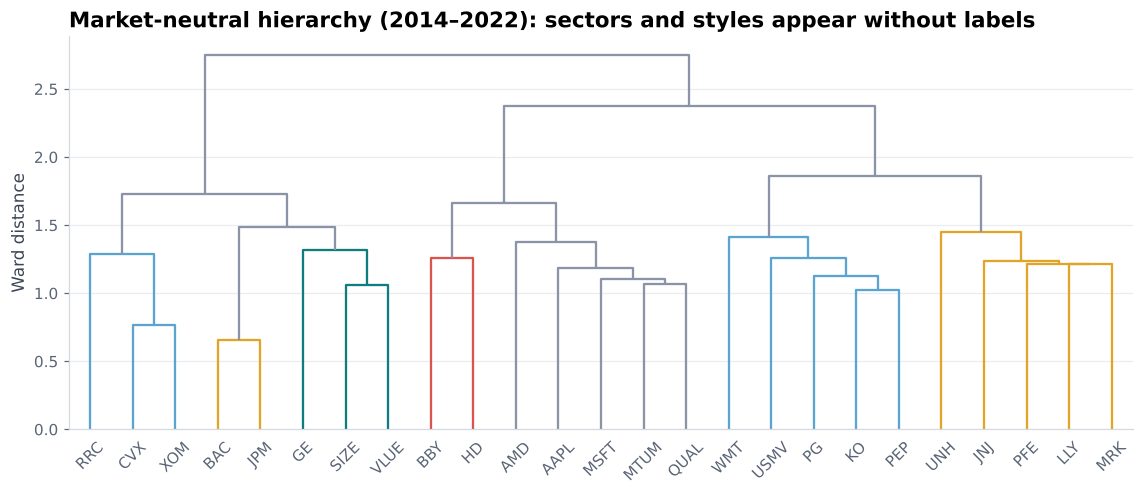

,members,sectors (not used by the algorithm)
1,"CVX, RRC, XOM",energy
2,"BAC, GE, JPM, SIZE, VLUE","banks, factor ETF, industrial"
3,"BBY, HD",consumer
4,"AAPL, AMD, MSFT, MTUM, QUAL","factor ETF, tech"
5,"KO, PEP, PG, WMT, USMV","factor ETF, staples"
6,"JNJ, LLY, MRK, PFE, UNH",health


In [5]:
Zs = (returns - returns.mean()) / returns.std()
w, v = np.linalg.eigh(C_raw.values)
market = Zs.values @ v[:, -1]                                  # first principal component = market mode
beta_m = Zs.values.T @ market / (market @ market)
resid = Zs.values - np.outer(market, beta_m)
C_rel = pd.DataFrame(np.corrcoef(resid, rowvar=False), index=C_raw.index, columns=C_raw.index)

D = np.sqrt(2 * (1 - C_rel.clip(-1, 1)))
Z = linkage(squareform(D.values, checks=False), method="ward")
groups = pd.Series(fcluster(Z, t=6, criterion="maxclust"), index=C_rel.index, name="balance")
order = dendrogram(Z, no_plot=True, labels=C_rel.index.tolist())["ivl"]

fig, ax = plt.subplots(figsize=(10.5, 4.6))
dendrogram(Z, labels=C_rel.index.tolist(), ax=ax, color_threshold=Z[-6, 2], above_threshold_color=PALETTE["grey"],
           leaf_font_size=10)
ax.set_title("Market-neutral hierarchy (2014–2022): sectors and styles appear without labels")
ax.set_ylabel("Ward distance"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

table = pd.DataFrame({"members": {b: ", ".join(groups[groups == b].index) for b in sorted(groups.unique())},
                      "sectors (not used by the algorithm)": {b: ", ".join(sorted({SECTOR[t] for t in groups[groups == b].index}))
                                                              for b in sorted(groups.unique())}})
table

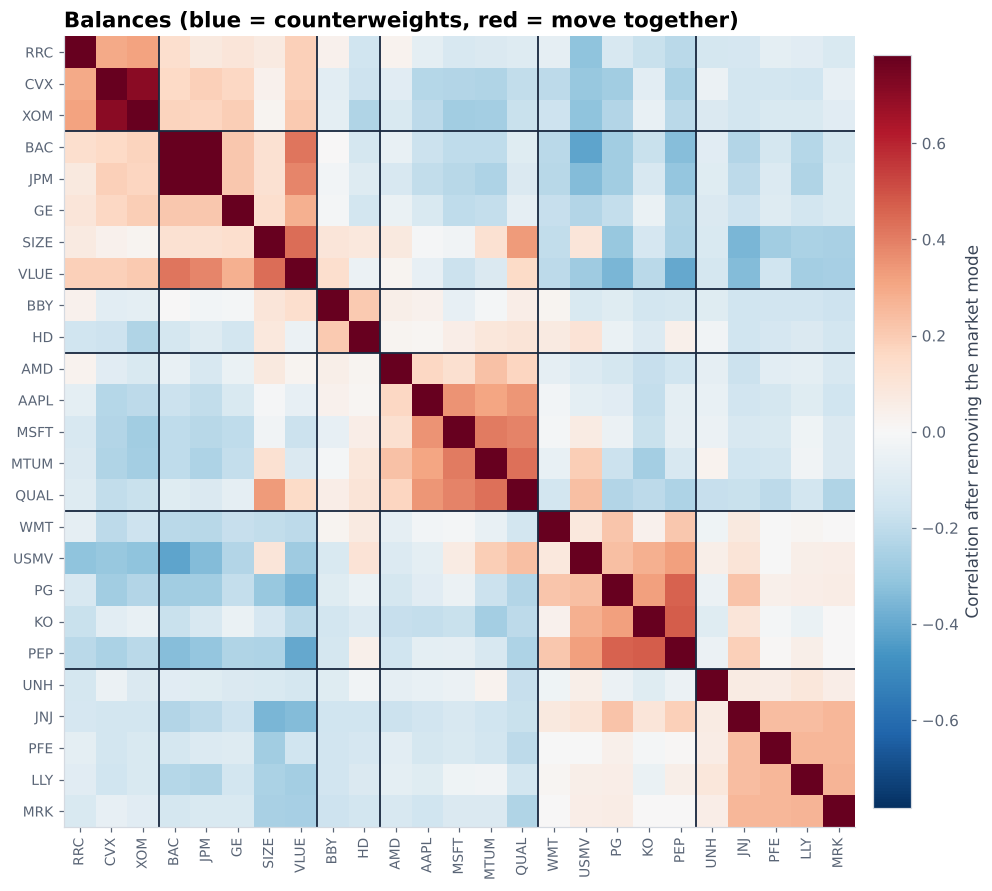

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 8.2))
M = C_rel.loc[order, order]
lim = np.abs(M.values[~np.eye(N, dtype=bool)]).max()
im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=9)
ax.grid(False)
g = groups.loc[order].to_numpy()
for k in np.where(np.diff(g) != 0)[0]:
    ax.axhline(k + 0.5, color=PALETTE["navy"], lw=1.2); ax.axvline(k + 0.5, color=PALETTE["navy"], lw=1.2)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("Correlation after removing the market mode")
ax.set_title("Balances (blue = counterweights, red = move together)")
plt.tight_layout(); plt.show()

**Counterweights.** Once the market mode is removed, groups do move *against* each other. For each balance, the table lists the group it is most negatively correlated with: its counterweight.


In [7]:
gm = {b: list(groups[groups == b].index) for b in sorted(groups.unique())}
between = pd.DataFrame({a: {b: C_rel.loc[gm[a], gm[b]].values.mean() for b in gm} for a in gm})
inside = {b: C_rel.loc[gm[b], gm[b]].values[~np.eye(len(gm[b]), dtype=bool)].mean() for b in gm}
cw = pd.DataFrame({"balance": {b: ", ".join(gm[b]) for b in gm},
                   "avg_corr_inside": {b: round(inside[b], 2) for b in gm},
                   "counterweight": {b: ", ".join(gm[between[b].drop(b).idxmin()]) for b in gm},
                   "avg_corr_with_counterweight": {b: round(between[b].drop(b).min(), 2) for b in gm}})
cw.reset_index(drop=True)

,balance,avg_corr_inside,counterweight,avg_corr_with_counterweight
0,"CVX, RRC, XOM",0.44,"KO, PEP, PG, WMT, USMV",-0.20
1,"BAC, GE, JPM, SIZE, VLUE",0.31,"KO, PEP, PG, WMT, USMV",-0.23
2,"BBY, HD",0.20,"JNJ, LLY, MRK, PFE, UNH",-0.13
3,"AAPL, AMD, MSFT, MTUM, QUAL",0.29,"CVX, RRC, XOM",-0.16
4,"KO, PEP, PG, WMT, USMV",0.26,"BAC, GE, JPM, SIZE, VLUE",-0.23
5,"JNJ, LLY, MRK, PFE, UNH",0.18,"BAC, GE, JPM, SIZE, VLUE",-0.19


## 4. Experiment 3: how much history does a balance need?

Every 20 trading days, estimate the correlation matrix from the previous **W** days (W = 5 … 250) and compare it with the correlation **realized over the next 60 days** (mean absolute error of the off-diagonal entries). Three estimators:

- **Sample** correlation over W days.
- **Ledoit–Wolf** shrinkage over W days [6].
- **Blend**: the five-day sample pulled toward a 250-day anchor, C = a·C₅ + (1−a)·C₂₅₀, with a chosen on the first half of the data and tested on the second half.

With 25 assets, a five-day matrix has rank at most 4: most of its structure is invented by noise.


In [8]:
def corr_from(X):
    c = np.corrcoef(X, rowvar=False)
    return np.nan_to_num(c, nan=0.0)

def lw_corr(X):
    cov = LedoitWolf().fit(X).covariance_
    d = np.sqrt(np.diag(cov)); return cov / np.outer(d, d)

R = returns.values
iu = np.triu_indices(N, 1)
HORIZON, STEP, ANCHOR = 60, 20, 250
dates = list(range(ANCHOR, len(R) - HORIZON, STEP))
windows = [5, 10, 20, 60, 120, 250]

def err(est, real):
    return np.abs(est[iu] - real[iu]).mean()

rows = []
for t in dates:
    real = corr_from(R[t:t + HORIZON])
    for W in windows:
        X = R[t - W:t]
        rows.append(dict(t=t, W=W, sample=err(corr_from(X), real), ledoit_wolf=err(lw_corr(X), real)))
win = pd.DataFrame(rows)

# Blend of the 5-day view with a 250-day anchor; choose a on the first half, test on the second
half = dates[len(dates) // 2]
alphas = np.linspace(0, 1, 21)
def blend_err(a, ts):
    return np.mean([err(a * corr_from(R[t - 5:t]) + (1 - a) * corr_from(R[t - ANCHOR:t]), corr_from(R[t:t + HORIZON])) for t in ts])
train_ts = [t for t in dates if t < half]; test_ts = [t for t in dates if t >= half]
a_star = alphas[np.argmin([blend_err(a, train_ts) for a in alphas])]
summary = win[win.t >= half].groupby("W")[["sample", "ledoit_wolf"]].mean()
print(f"Best weight on the 5-day view (chosen on 2015-2018): a = {a_star:.2f}")
print(f"Test-period error · 5-day sample: {summary.loc[5, 'sample']:.3f} | 5-day blend: {blend_err(a_star, test_ts):.3f} | 250-day sample: {summary.loc[250, 'sample']:.3f}")
summary.round(3)

Best weight on the 5-day view (chosen on 2015-2018): a = 0.05
Test-period error · 5-day sample: 0.397 | 5-day blend: 0.202 | 250-day sample: 0.208


,sample,ledoit_wolf
W,,
5,0.397,0.331
10,0.287,0.297
20,0.231,0.255
60,0.197,0.209
120,0.191,0.193
250,0.208,0.202


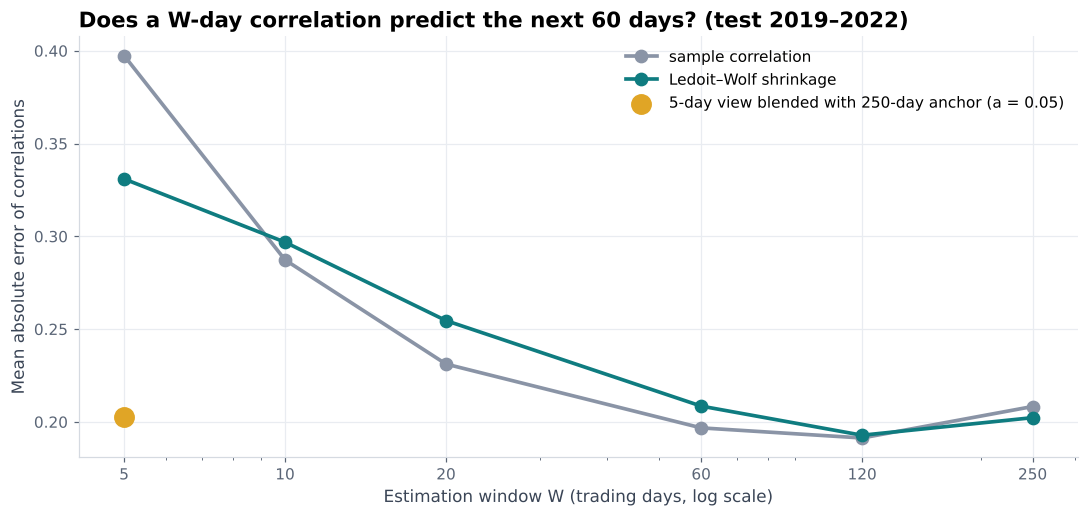

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(summary.index, summary["sample"], "-o", color=PALETTE["grey"], lw=2.4, ms=8, label="sample correlation")
ax.plot(summary.index, summary["ledoit_wolf"], "-o", color=PALETTE["teal"], lw=2.4, ms=8, label="Ledoit–Wolf shrinkage")
b = blend_err(a_star, test_ts)
ax.scatter([5], [b], s=160, color=PALETTE["gold"], zorder=5, label=f"5-day view blended with 250-day anchor (a = {a_star:.2f})")
ax.set_xscale("log"); ax.set_xticks(windows); ax.set_xticklabels(windows)
ax.set_title("Does a W-day correlation predict the next 60 days? (test 2019–2022)")
ax.set_xlabel("Estimation window W (trading days, log scale)"); ax.set_ylabel("Mean absolute error of correlations")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 5. When balances collapse: the market mode over time

The share of variance explained by the largest eigenvalue, computed over rolling 60-day windows, measures how much the market moves as one block [1, 7].


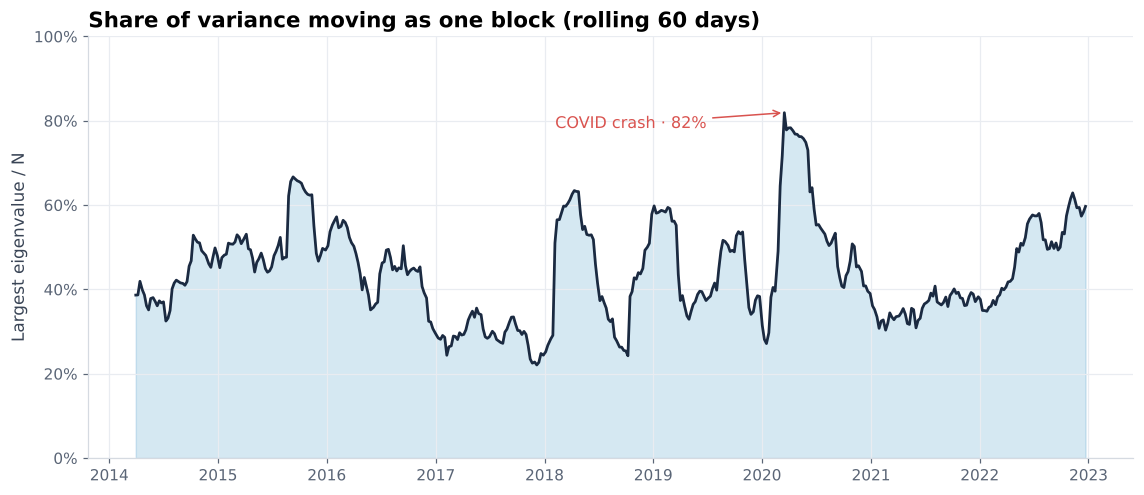

In [10]:
roll = []
for t in range(60, len(R), 5):
    e = np.linalg.eigvalsh(corr_from(R[t - 60:t]))
    roll.append((returns.index[t - 1], e[-1] / N))
roll = pd.DataFrame(roll, columns=["date", "market_mode"]).set_index("date")

fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.fill_between(roll.index, roll.market_mode, color=PALETTE["sky"], alpha=0.25)
ax.plot(roll.index, roll.market_mode, color=PALETTE["navy"], lw=1.8)
peak = roll.market_mode.idxmax()
ax.annotate(f"COVID crash · {roll.market_mode.max():.0%}", (peak, roll.market_mode.max()),
            xytext=(-150, -10), textcoords="offset points", color=PALETTE["coral"], fontsize=10.5,
            arrowprops=dict(arrowstyle="->", color=PALETTE["coral"]))
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Share of variance moving as one block (rolling 60 days)")
ax.set_ylabel("Largest eigenvalue / N")
plt.tight_layout(); plt.show()

## 6. Discussion

Exact values are in the outputs above.

- **Only a few directions are signal.** Three eigenvalues exceed the random-matrix bound; the market mode alone carries about half of all variance [1, 2]. Clustering the raw matrix therefore finds one giant block.
- **Balances appear once the market mode is removed.** Without being told sectors, the market-neutral hierarchy separates energy; banks with industrials and the value and size ETFs; consumer discretionary; technology with the momentum and quality ETFs; health care; and staples with the low-volatility ETF. The factor ETFs land exactly with the stocks that define their style. This reproduces Mantegna's result [3] on a modern sample and gives Equilibra's balances an objective definition, including real counterweights (negative market-neutral correlation).
- **A five-day correlation alone is mostly noise as a forecast.** Its error is about twice that of a 60–120-day window. Ledoit–Wolf shrinkage helps the five-day window but slightly hurts the 10–60-day ones, because its target (no correlation) ignores the strong market mode [6]. The best blend gives the five-day view only about 5% weight when predicting the next quarter. For Equilibra this suggests a concrete design change: keep the weekly view as a description of *what moved this week*, and show it **as a deviation from the long-run balance** rather than as a stand-alone matrix that users might read as a forecast.
- **In a crisis, balances collapse.** During the COVID crash the market mode explained most of the variance [7]: any balance that relies on low correlation weakens exactly when it is needed.

**Limitations.** Twenty large US stocks and five factor ETFs, data ending in 2022, no transaction costs, and correlation (linear, symmetric) as the only dependence measure.

## 7. Thesis questions

1. **Grading user theses.** Users of Equilibra write theses ("energy will hedge my tech holdings this quarter"). Can the system grade them automatically against denoised balances, and can the grades calibrate how much an AI assistant should trust each user's reasoning?
2. **Regime detection for agents.** Can a change-point model on the market mode tell an AI assistant when the balances it learned no longer hold, so it flags its own uncertainty?
3. **Beyond correlation.** Do non-linear dependence measures (rank correlation, mutual information, tail dependence) give more stable balances for short windows?

## References

1. Laloux, L., Cizeau, P., Bouchaud, J.-P., & Potters, M. (1999). *Noise dressing of financial correlation matrices.* Physical Review Letters, 83(7), 1467–1470.
2. Plerou, V., Gopikrishnan, P., Rosenow, B., Amaral, L. A. N., & Stanley, H. E. (1999). *Universal and nonuniversal properties of cross correlations in financial time series.* Physical Review Letters, 83(7), 1471–1474.
3. Mantegna, R. N. (1999). *Hierarchical structure in financial markets.* The European Physical Journal B, 11(1), 193–197.
4. Marti, G., Nielsen, F., Bińkowski, M., & Donnat, P. (2021). *A review of two decades of correlations, hierarchies, networks and clustering in financial markets.* In Progress in Information Geometry, Springer. arXiv:1703.00485.
5. López de Prado, M. (2016). *Building diversified portfolios that outperform out of sample.* The Journal of Portfolio Management, 42(4), 59–69.
6. Ledoit, O., & Wolf, M. (2004). *A well-conditioned estimator for large-dimensional covariance matrices.* Journal of Multivariate Analysis, 88(2), 365–411.
7. Longin, F., & Solnik, B. (2001). *Extreme correlation of international equity markets.* The Journal of Finance, 56(2), 649–676.
8. Xiao, Y., Sun, E., Luo, D., & Wang, W. (2024). *TradingAgents: Multi-Agents LLM Financial Trading Framework.* arXiv:2412.20138.

**Data:** daily prices from the public datasets distributed with the open-source library skfolio (`load_sp500_dataset`, `load_factors_dataset`).
